In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Raw shape:", df.shape)

# Fix TotalCharges (blank strings -> NaN -> numeric)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with missing TotalCharges:", df["TotalCharges"].isna().sum())

df = df.dropna(subset=["TotalCharges"])
df = df.drop(columns=["customerID"])

# Encode target
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Clean shape:", df.shape)
df.head()

Raw shape: (7043, 21)
Rows with missing TotalCharges: 11
Clean shape: (7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


C:\Users\janaa\AppData\Local\Temp\ipykernel_32576\492340914.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), palette="Set2")


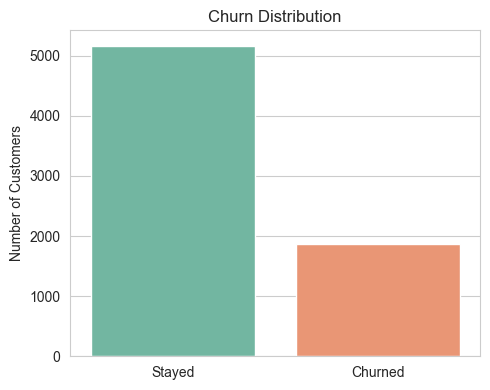

Churn
Stayed     0.734
Churned    0.266
Name: proportion, dtype: float64


In [3]:
# Class balance
plt.figure(figsize=(5, 4))
sns.countplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), palette="Set2")
plt.title("Churn Distribution")
plt.xlabel("")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print(df["Churn"].value_counts(normalize=True).rename({0: "Stayed", 1: "Churned"}).round(3))

C:\Users\janaa\AppData\Local\Temp\ipykernel_32576\915256525.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), y=df["tenure"], ax=axes[0], palette="Set2")
C:\Users\janaa\AppData\Local\Temp\ipykernel_32576\915256525.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), y=df["MonthlyCharges"], ax=axes[1], palette="Set2")


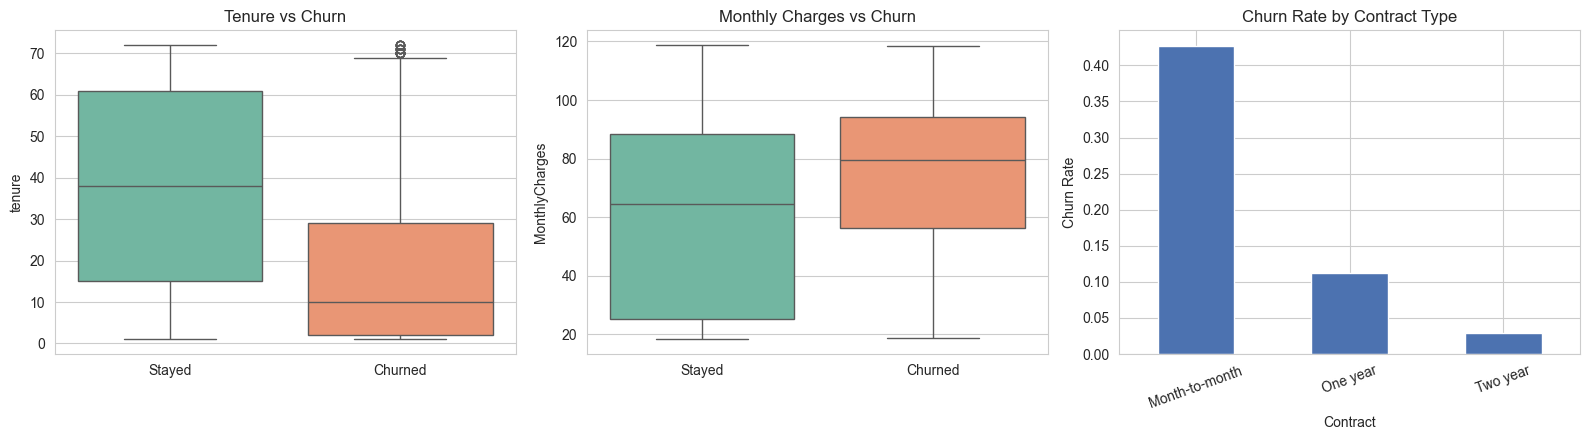

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), y=df["tenure"], ax=axes[0], palette="Set2")
axes[0].set_title("Tenure vs Churn")
axes[0].set_xlabel("")

sns.boxplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), y=df["MonthlyCharges"], ax=axes[1], palette="Set2")
axes[1].set_title("Monthly Charges vs Churn")
axes[1].set_xlabel("")

churn_by_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index")[1]
churn_by_contract.plot(kind="bar", ax=axes[2], color="#4C72B0")
axes[2].set_title("Churn Rate by Contract Type")
axes[2].set_ylabel("Churn Rate")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [5]:
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
for col in binary_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

df["gender"] = df["gender"].map({"Male": 1, "Female": 0})

multi_cat_cols = [
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaymentMethod"
]

df_encoded = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

print("Final feature count:", X.shape[1])
X.head()

Final feature count: 30


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,True,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,False,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,False,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,True,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,False,...,False,False,False,False,False,False,False,False,True,False


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (5625, 30)
Test shape: (1407, 30)


In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: Gradient Boosting


In [9]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    })

    print(f"\n{'='*55}")
    print(f"Model: {name}")
    print(f"{'='*55}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))


Model: Logistic Regression
Accuracy : 0.8038
Precision: 0.6476
Recall   : 0.5749
F1-score : 0.6091

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Model: Random Forest
Accuracy : 0.7932
Precision: 0.6416
Recall   : 0.5027
F1-score : 0.5637

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.83      0.90      0.86      1033
     Churned       0.64      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


Model: Gradient Boosting
Accuracy : 0.7953
Precision: 0.6378
Recall   : 0.5321
F1-score : 0.5802

Class

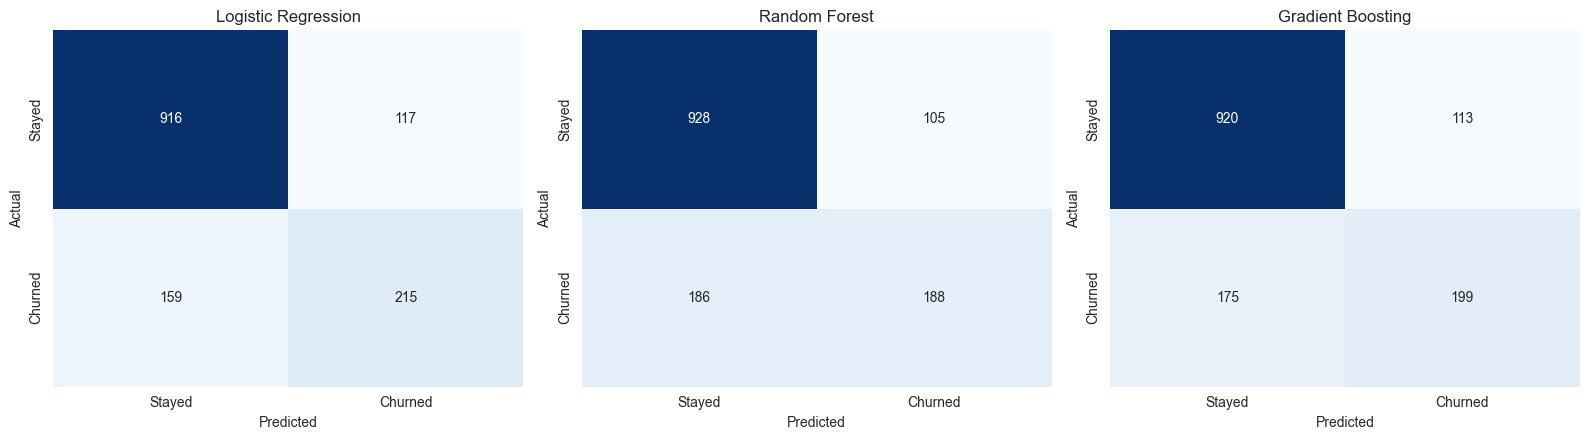

In [10]:
# Confusion matrices for all three models, side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"]
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [11]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8038,0.6476,0.5749,0.6091
Random Forest,0.7932,0.6416,0.5027,0.5637
Gradient Boosting,0.7953,0.6378,0.5321,0.5802


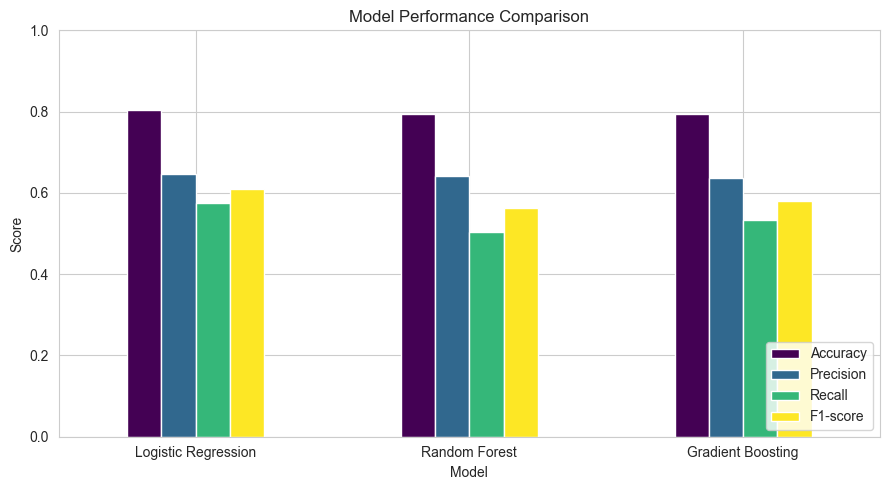

In [12]:
results_df.plot(kind="bar", figsize=(9, 5), colormap="viridis")
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:
cv_results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy")
    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results).set_index("Model").round(4)
cv_df

,CV Mean Accuracy,CV Std
Model,,
Logistic Regression,0.8025,0.0123
Random Forest,0.7906,0.0104
Gradient Boosting,0.7988,0.0136


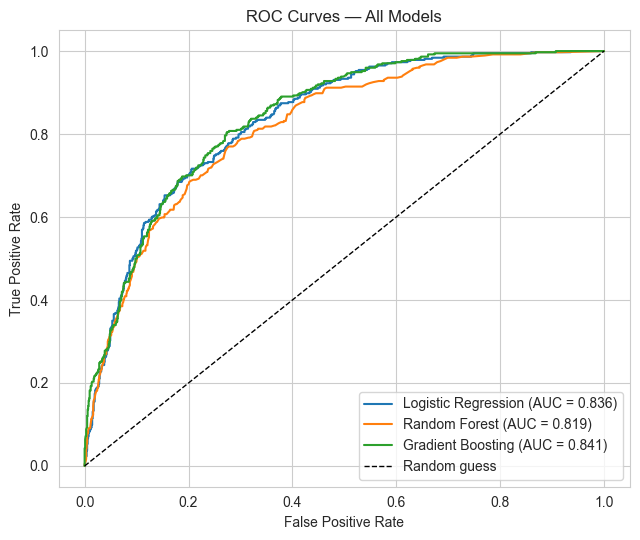

In [14]:
plt.figure(figsize=(6.5, 5.5))

for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

C:\Users\janaa\AppData\Local\Temp\ipykernel_32576\4127573563.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="viridis")


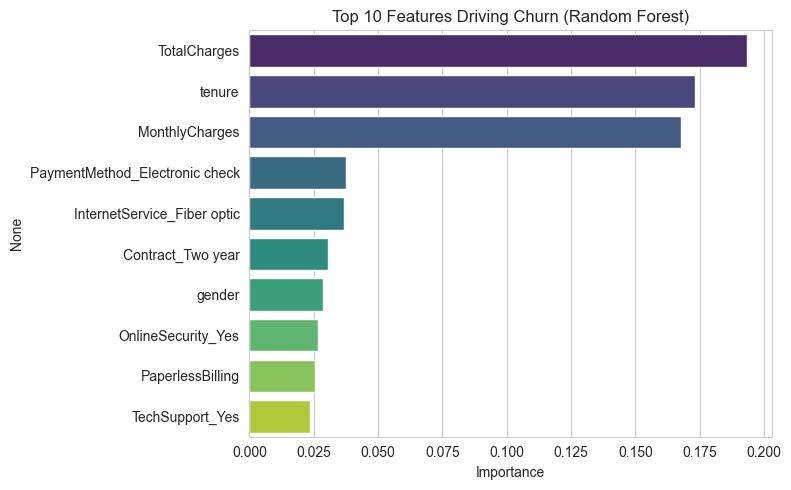

In [15]:
importances = pd.Series(
    trained_models["Random Forest"].feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Top 10 Features Driving Churn (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()